In [ ]:
#Spatiotemporal Moran Index for 8 types of Weights (not include SOTA post-2024)

In [ ]:
#A) Evaluation of Moran (Moran-2Di for WST+ Moran’s I each year for Wbd) + Monte Carlo + CI95

In [ ]:
#1) Install & Upload

!pip -q install numpy pandas openpyxl

from google.colab import files
uploaded = files.upload()  # upload: data.xlsx dan W8.xlsx

Saving W8.xlsx to W8 (2).xlsx
Saving data.xlsx to data (3).xlsx


In [ ]:
#2) Load data

import numpy as np
import pandas as pd

DATA_PATH = "data.xlsx"
W8_PATH   = "W8.xlsx"   # ganti jika nama file Anda berbeda

df = pd.read_excel(DATA_PATH)

# pastikan kolom ada
print(df.columns)
print("Shape:", df.shape)
print("Year counts:", df["Waktu"].value_counts().sort_index().to_dict())

# z-score dari Y untuk N=175
y = df["Y"].astype(float).to_numpy()
z = (y - y.mean()) / y.std(ddof=0)

years = df["Waktu"].to_numpy()
N = len(z)
print("N =", N)

Index(['Waktu', 'Lokasi', 'Y', 'Y_(t-1)'], dtype='object')
Shape: (175, 4)
Year counts: {2018: 35, 2019: 35, 2020: 35, 2021: 35, 2022: 35}
N = 175


In [ ]:
#3) Function of (Moran-type) Index and Monte Carlo permutation + CI95

def moran_index(z_vec: np.ndarray, W: np.ndarray) -> float:
    """
    Moran-type index:
    I = (n/S0) * (z' W z) / (z' z)
    Works for both n=175 (W_ST) and n=35 (W_bd per-year).
    """
    z_col = np.asarray(z_vec, dtype=float).reshape(-1, 1)
    n = z_col.shape[0]
    S0 = float(W.sum())
    if S0 == 0:
        raise ValueError("S0 = sum(W) is zero.")
    # Access the single element from the 1x1 array to avoid DeprecationWarning
    num = float((z_col.T @ W @ z_col)[0, 0])
    den = float((z_col.T @ z_col)[0, 0])
    return (n / S0) * (num / den)


def mc_perm_ci(
    z_vec: np.ndarray,
    W: np.ndarray,
    n_perm: int = 999,
    seed: int = 2026,
    two_sided: bool = True,
):
    """
    Monte Carlo permutation test (unrestricted permutation of labels).
    Returns I_obs, p_value, perm_mean, perm_std, ci95_low, ci95_high
    """
    rng = np.random.default_rng(seed)
    z_vec = np.asarray(z_vec, dtype=float).ravel()

    I_obs = moran_index(z_vec, W)

    I_perm = np.empty(n_perm, dtype=float)
    for b in range(n_perm):
        z_perm = rng.permutation(z_vec)
        I_perm[b] = moran_index(z_perm, W)

    if two_sided:
        p_value = (np.sum(np.abs(I_perm) >= np.abs(I_obs)) + 1) / (n_perm + 1)
    else:
        p_value = (np.sum(I_perm >= I_obs) + 1) / (n_perm + 1)

    perm_mean = float(I_perm.mean())
    perm_std  = float(I_perm.std(ddof=1))
    ci95_low  = float(np.percentile(I_perm, 2.5))
    ci95_high = float(np.percentile(I_perm, 97.5))

    return I_obs, p_value, perm_mean, perm_std, ci95_low, ci95_high


def mc_perm_ci_within_year(
    z_vec: np.ndarray,
    years_vec: np.ndarray,
    W_ST: np.ndarray,
    n_perm: int = 999,
    seed: int = 2026,
    two_sided: bool = True
):
    """
    Monte Carlo permutation test for Moran-2Di with within-year permutation.
    W_ST fixed (175x175), shuffle z within each year.
    """
    rng = np.random.default_rng(seed)
    z_vec = np.asarray(z_vec, dtype=float).ravel()
    years_vec = np.asarray(years_vec).ravel()

    I_obs = moran_index(z_vec, W_ST)

    unique_years = np.unique(years_vec)
    year_indices = {yr: np.where(years_vec == yr)[0] for yr in unique_years}

    I_perm = np.empty(n_perm, dtype=float)
    for b in range(n_perm):
        z_perm = z_vec.copy()
        for yr, idx in year_indices.items():
            z_perm[idx] = rng.permutation(z_perm[idx])
        I_perm[b] = moran_index(z_perm, W_ST)

    if two_sided:
        p_value = (np.sum(np.abs(I_perm) >= np.abs(I_obs)) + 1) / (n_perm + 1)
    else:
        p_value = (np.sum(I_perm >= I_obs) + 1) / (n_perm + 1)

    perm_mean = float(I_perm.mean())
    perm_std  = float(I_perm.std(ddof=1))
    ci95_low  = float(np.percentile(I_perm, 2.5))
    ci95_high = float(np.percentile(I_perm, 97.5))

    return I_obs, p_value, perm_mean, perm_std, ci95_low, ci95_high

In [ ]:
#4) Proccessing 7 sheet of WST(175×175) + 1 sheet Wbd(35×35)

sheets_needed = [
    "W_ST^Q",
    "W_ST^Q10",
    "W_ST^Qq",
    "W_ST^Q10q",
    "W_ST^Qr",
    "W_ST^Q10r",
    "W_bdst",
    "W_bd"
]

xls = pd.ExcelFile(W8_PATH)
print("Sheets found:", xls.sheet_names)

# --- A) Results for W_ST (175x175) ---
res_st = []

for sh in sheets_needed:
    if sh not in xls.sheet_names:
        print(f"[MISSING] {sh} not found in W8.xlsx")
        continue

    Wmat = pd.read_excel(W8_PATH, sheet_name=sh, header=None).to_numpy(dtype=float)

    if sh != "W_bd":
        # must be 175x175
        if Wmat.shape != (N, N):
            print(f"[SKIP] {sh} shape {Wmat.shape} != ({N},{N})")
            continue

        I_obs, pval, pmean, pstd, ciL, ciH = mc_perm_ci_within_year(
            z, years, Wmat,
            n_perm=999, seed=2026, two_sided=True
        )
        res_st.append({
            "Weight": sh,
            "I_obs": I_obs,
            "p_value": pval,
            "perm_mean": pmean,
            "perm_std": pstd,
            "ci95_low": ciL,
            "ci95_high": ciH
        })

res_st_df = pd.DataFrame(res_st).sort_values("Weight").reset_index(drop=True)
res_st_df

Sheets found: ['W_ST^Q', 'W_ST^Q10', 'W_ST^Qq', 'W_ST^Q10q', 'W_ST^Qr', 'W_ST^Q10r', 'W_bdst', 'W_bd']


,Weight,I_obs,p_value,perm_mean,perm_std,ci95_low,ci95_high
0,W_ST^Q,0.653762,0.001,0.414587,0.020957,0.373852,0.456039
1,W_ST^Q10,0.633412,0.001,0.535381,0.019726,0.498970,0.574143
2,W_ST^Q10q,0.754757,0.001,0.413346,0.027387,0.358525,0.469582
3,W_ST^Q10r,0.770530,0.001,0.420612,0.028036,0.365789,0.478030
4,W_ST^Qq,0.757131,0.001,0.413745,0.026930,0.360500,0.469300
5,W_ST^Qr,0.765697,0.001,0.413458,0.027687,0.358741,0.469522
6,W_bdst,0.695603,0.001,0.328278,0.032877,0.265116,0.393176


In [ ]:
#5) Special for Wbd(35×35): Moran’s I Per Year+ CI95 + p-value
####Notes: the order of 35 location in each year in the data.xlsx same with the order of row/column at W_bd.


# --- B) Results for W_bd per-year (35x35) ---
res_bd_year = []

if "W_bd" in xls.sheet_names:
    W_bd = pd.read_excel(W8_PATH, sheet_name="W_bd", header=None).to_numpy(dtype=float)

    if W_bd.shape != (35, 35):
        print(f"[WARN] W_bd shape is {W_bd.shape}, expected (35,35)")
    else:
        for yr in sorted(df["Waktu"].unique()):
            df_y = df[df["Waktu"] == yr].copy()

            # z-score within year (common for per-year Moran I)
            y_yr = df_y["Y"].astype(float).to_numpy()
            z_yr = (y_yr - y_yr.mean()) / y_yr.std(ddof=0)

            I_obs, pval, pmean, pstd, ciL, ciH = mc_perm_ci(
                z_yr, W_bd,
                n_perm=999, seed=2026, two_sided=True
            )
            res_bd_year.append({
                "Weight": "W_bd",
                "Year": int(yr),
                "I_obs": I_obs,
                "p_value": pval,
                "perm_mean": pmean,
                "perm_std": pstd,
                "ci95_low": ciL,
                "ci95_high": ciH
            })

res_bd_year_df = pd.DataFrame(res_bd_year).sort_values("Year").reset_index(drop=True)
res_bd_year_df


,Weight,Year,I_obs,p_value,perm_mean,perm_std,ci95_low,ci95_high
0,W_bd,2018,0.266602,0.001,-0.030774,0.045946,-0.116382,0.072793
1,W_bd,2019,0.299506,0.001,-0.031267,0.046904,-0.111287,0.084796
2,W_bd,2020,0.099465,0.068,-0.031162,0.048752,-0.116270,0.078618
3,W_bd,2021,0.068761,0.240,-0.030660,0.047282,-0.108835,0.083082
4,W_bd,2022,0.091310,0.075,-0.029842,0.046255,-0.111436,0.075708


In [ ]:
#6) Export the results

res_st_df.to_csv("moran2di_mc_summary_WST.csv", index=False)
res_bd_year_df.to_csv("moranI_mc_summary_Wbd_by_year.csv", index=False)

from google.colab import files
files.download("moran2di_mc_summary_WST.csv")
files.download("moranI_mc_summary_Wbd_by_year.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Visualization of Monte Carlo Permutation Results

The following is a visualization of the Monte Carlo permutation results for the WST and Wbd weights.*italicized text*

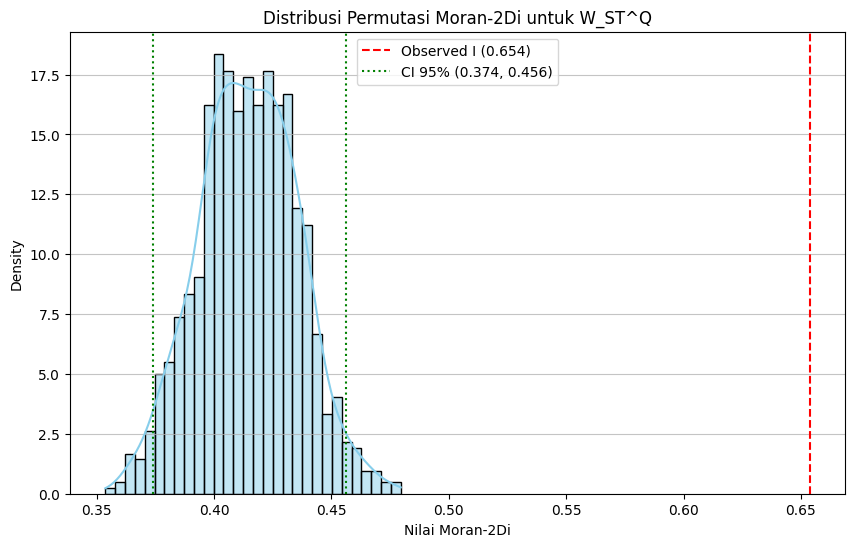

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# --- Visualization for W_ST (example: W_ST^Q) ---

# Ambil data untuk W_ST^Q
w_st_q_data = res_st_df[res_st_df['Weight'] == 'W_ST^Q'].iloc[0]
ob_I_st_q = w_st_q_data['I_obs']
ciL_st_q = w_st_q_data['ci95_low']
ciH_st_q = w_st_q_data['ci95_high']

# Regenerate permutation values for W_ST^Q for plotting
W_ST_Q_mat = pd.read_excel(W8_PATH, sheet_name='W_ST^Q', header=None).to_numpy(dtype=float)

rng = np.random.default_rng(2026)
n_perm = 999
I_perm_st_q = np.empty(n_perm, dtype=float)

unique_years = np.unique(years)
year_indices = {yr: np.where(years == yr)[0] for yr in unique_years}

for b in range(n_perm):
    z_perm = z.copy()
    for yr, idx in year_indices.items():
        z_perm[idx] = rng.permutation(z_perm[idx])
    I_perm_st_q[b] = moran_index(z_perm, W_ST_Q_mat)


plt.figure(figsize=(10, 6))
sns.histplot(I_perm_st_q, bins=30, kde=True, color='skyblue', stat='density')
plt.axvline(ob_I_st_q, color='red', linestyle='--', label=f'Observed I ({ob_I_st_q:.3f})')
plt.axvline(ciL_st_q, color='green', linestyle=':', label=f'CI 95% ({ciL_st_q:.3f}, {ciH_st_q:.3f})')
plt.axvline(ciH_st_q, color='green', linestyle=':')
plt.title('Distribusi Permutasi Moran-2Di untuk W_ST^Q')
plt.xlabel('Nilai Moran-2Di')
plt.ylabel('Density')
plt.legend()
plt.grid(axis='y', alpha=0.75)
plt.show()

### Visualisasi untuk W_bd (per Tahun)

Untuk bobot W_bd, kita akan melihat distribusi permutasi untuk setiap tahun (2018-2022).

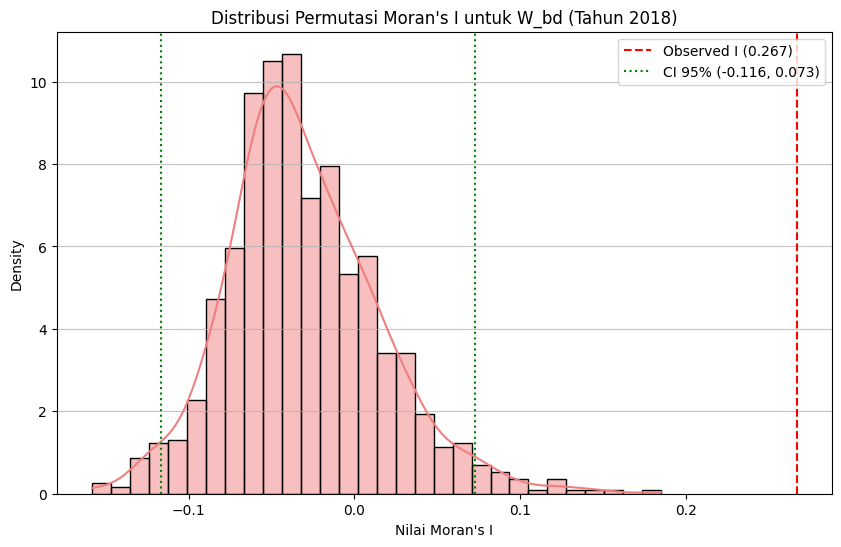

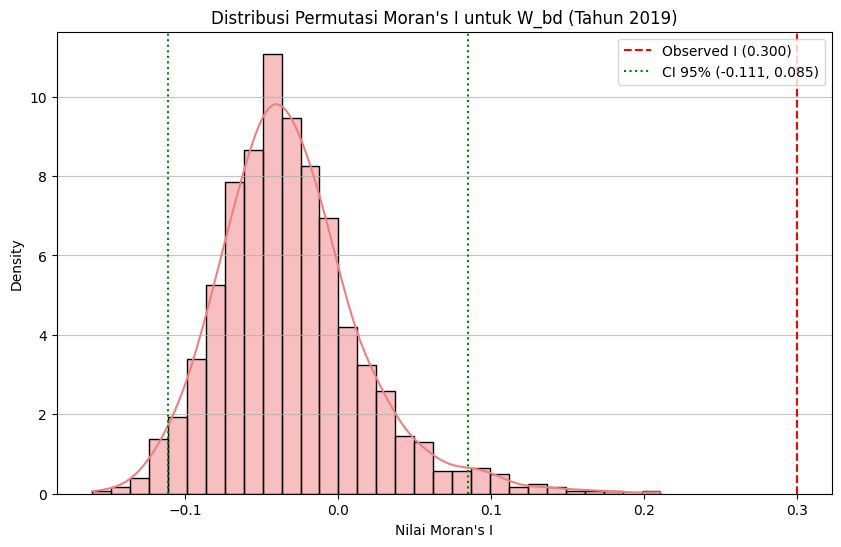

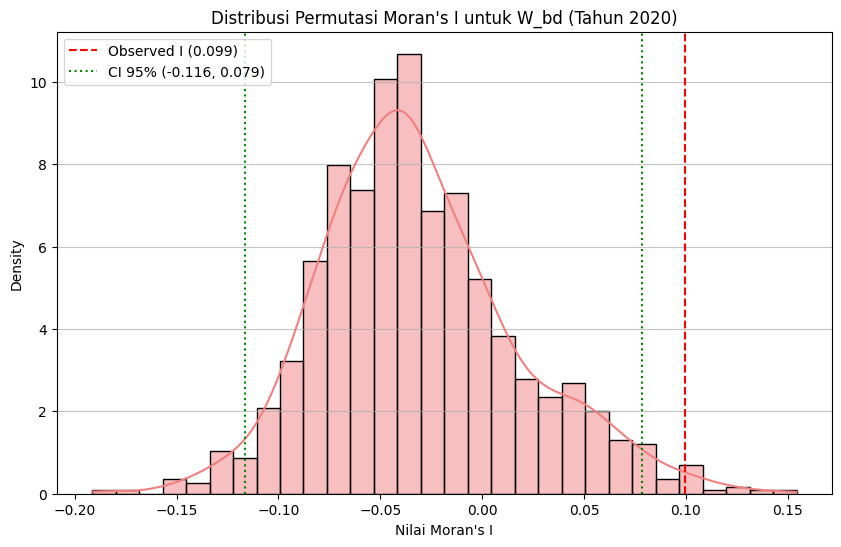

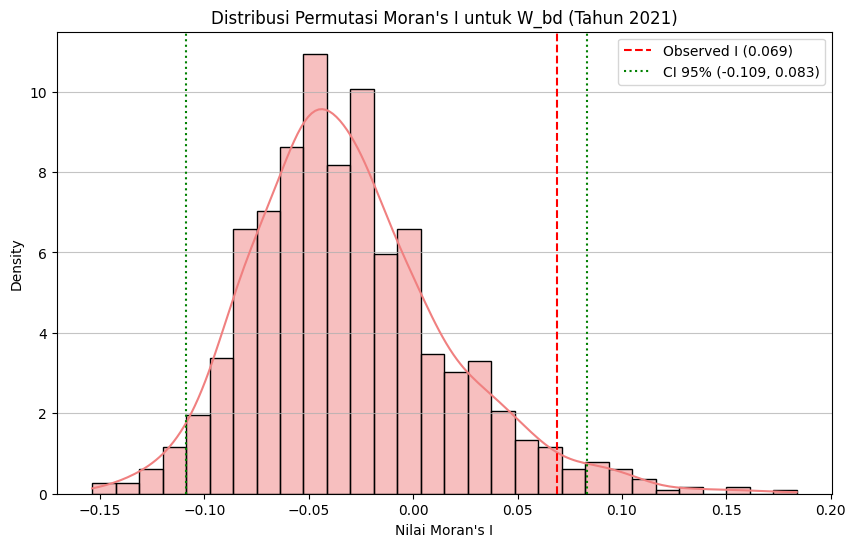

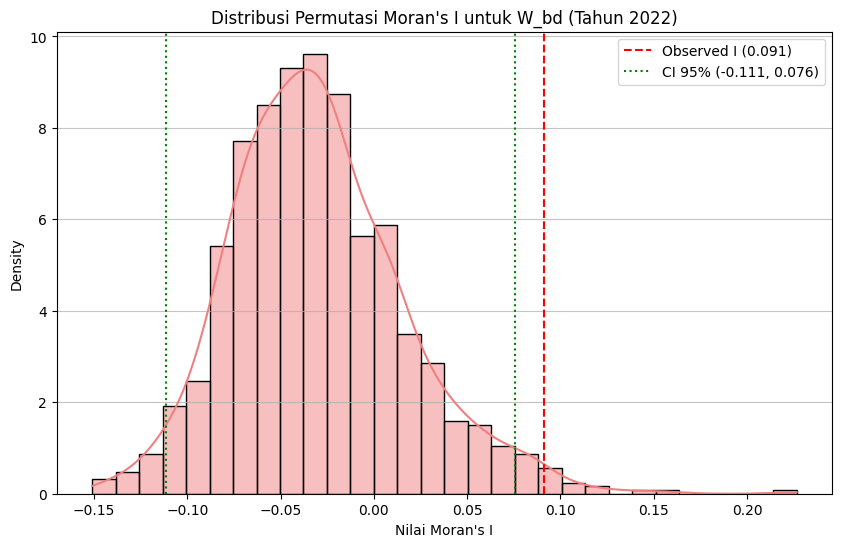

In [ ]:
# --- Visualization for W_bd per year ---

# Load W_bd matrix once
W_bd_mat = pd.read_excel(W8_PATH, sheet_name='W_bd', header=None).to_numpy(dtype=float)

n_perm = 999
seed = 2026 # Use the same seed for reproducibility

for yr in sorted(df["Waktu"].unique()):
    df_y = df[df["Waktu"] == yr].copy()
    y_yr = df_y["Y"].astype(float).to_numpy()
    z_yr = (y_yr - y_yr.mean()) / y_yr.std(ddof=0)

    # Get observed I and CI for the current year from the dataframe
    yearly_data = res_bd_year_df[res_bd_year_df['Year'] == yr].iloc[0]
    ob_I_bd = yearly_data['I_obs']
    ciL_bd = yearly_data['ci95_low']
    ciH_bd = yearly_data['ci95_high']

    # Regenerate permutation values for W_bd for plotting for the current year
    rng = np.random.default_rng(seed)
    I_perm_bd = np.empty(n_perm, dtype=float)
    for b in range(n_perm):
        z_perm = rng.permutation(z_yr)
        I_perm_bd[b] = moran_index(z_perm, W_bd_mat)

    plt.figure(figsize=(10, 6))
    sns.histplot(I_perm_bd, bins=30, kde=True, color='lightcoral', stat='density')
    plt.axvline(ob_I_bd, color='red', linestyle='--', label=f'Observed I ({ob_I_bd:.3f})')
    plt.axvline(ciL_bd, color='green', linestyle=':', label=f'CI 95% ({ciL_bd:.3f}, {ciH_bd:.3f})')
    plt.axvline(ciH_bd, color='green', linestyle=':')
    plt.title(f'Distribusi Permutasi Moran\'s I untuk W_bd (Tahun {yr})')
    plt.xlabel('Nilai Moran\'s I')
    plt.ylabel('Density')
    plt.legend()
    plt.grid(axis='y', alpha=0.75)
    plt.show()

## Interpretation of p-value Significance

In the context of the Moran's I and Moran-2Di tests, the p-value indicates the probability of observing a Moran's I value that is as strong or stronger than the observed one, if there is no spatial autocorrelation (the null hypothesis).

Typically, a p-value less than the chosen significance level (e.g., 0.05 or 0.01) indicates sufficient evidence to reject the null hypothesis, meaning there is statistically significant spatial autocorrelation.

### Results for WST (Moran-2Di)

Based on `res_st_df`:

```
Weight     I_obs  p_value  perm_mean  perm_std  ci95_low  ci95_high
0     W_ST^Q  0.653762    0.001   0.414587  0.020957  0.373852   0.456039
1   W_ST^Q10  0.633412    0.001   0.535381  0.019726  0.498970   0.574143
2  W_ST^Q10q  0.754757    0.001   0.413346  0.027387  0.358525   0.469582
3  W_ST^Q10r  0.770530    0.001   0.420612  0.028036  0.365789   0.478030
4    W_ST^Qq  0.757131    0.001   0.413745  0.026930  0.360500   0.469300
5    W_ST^Qr  0.765697    0.001   0.413458  0.027687  0.358741   0.469522
6     W_bdst  0.695603    0.001   0.328278  0.032877  0.265116   0.393176
```

For all WST weighting types evaluated (`W_ST^Q`, `W_ST^Q10`, `W_ST^Qq`, `W_ST^Q10q`, `W_ST^Qr`, `W_ST^Q10r`, `W_bdst`), all p-values ​​are 0.001. This is a very low value, well below common significance thresholds (e.g., 0.05 or 0.01). This indicates that there is statistically significant spatial autocorrelation in the data when using WST weighting. In other words, the observed spatial pattern in the data (similar `Y` values ​​located close together) is likely not random.

### Results for Wbd (Moran's I per Year)

Based on `res_bd_year_df`:

```
Weight  Year     I_obs  p_value  perm_mean  perm_std  ci95_low  ci95_high
0   W_bd  2018  0.266602    0.001  -0.030774  0.045946 -0.116382   0.072793
1   W_bd  2019  0.299506    0.001  -0.031267  0.046904 -0.111287   0.084796
2   W_bd  2020  0.099465    0.068  -0.031162  0.048752 -0.116270   0.078618
3   W_bd  2021  0.068761    0.240  -0.030660  0.047282 -0.108835   0.083082
4   W_bd  2022  0.091310    0.075  -0.029842  0.046255 -0.111436   0.075708
```

For the `W_bd` weighting (spatial only), the interpretation varies by year:

* **Year 2018 and 2019**: The P-value is **0.001**, which is highly significant. This indicates significant spatial autocorrelation for those years.
* **Year 2020**: The P-value is **0.068**. Using a significance level of 0.05, this means we cannot reject the null hypothesis. In other words, at the 0.05 level, there is insufficient evidence to suggest significant spatial autocorrelation for 2020.
* **Year 2021**: The P-value is **0.240**, significantly higher than 0.05. This indicates no evidence of significant spatial autocorrelation for 2021.
* **Year 2022**: The P-value is **0.075**. Similar to 2020, at the 0.05 significance level, we cannot reject the null hypothesis, thus there is no evidence of significant spatial autocorrelation for 2022.

Overall, the Moran's-2Di results with WST weighting consistently show strong and significant spatial autocorrelation, while the Moran's I results per year with Wbd weighting indicate that spatial autocorrelation is significant only in the early years (2018-2019) and weakens or becomes insignificant in the later years (2020-2022).

## Formal Conclusions

This study explores the presence of spatial autocorrelation in the data using Moran's I and Moran-2Di indices, supported by Monte Carlo permutation tests to assess statistical significance. Two main types of spatial weighting are used: **W_ST (Weighting Spatio-Temporal)**, which measures 175x175, simultaneously accommodating both spatial and temporal dimensions; and **W_bd (Weighting Boundary/Distance)**, which measures 35x35, focusing on intra-annual spatial autocorrelation.

### Key Findings:

1. Spatial-Temporal Autocorrelation (W_ST):
* For all seven W_ST weighting variants tested (`W_ST^Q`, `W_ST^Q10`, `W_ST^Qq`, `W_ST^Q10q`, `W_ST^Qr`, `W_ST^Q10r`, and `W_bdst`), the Moran-2Di results consistently showed a very low **p-value (0.001)**. This indicates very strong evidence to reject the null hypothesis of no spatial-temporal autocorrelation. Thus, it can be concluded that there is a significant and positive spatial-temporal autocorrelation** in the data, indicating that similar `Y` values ​​tend to cluster not only in close proximity but also temporally.
* The observed Moran-2Di values ​​for the W_ST weighting are substantially higher than the average Moran-2Di values ​​from the permutation simulations, strengthening the conclusion that there is a structured, rather than random, spatio-temporal pattern.

2. **Annual Spatial Autocorrelation (W_bd)**:
* Moran's I test with the W_bd weighting indicates significant variation in spatial autocorrelation across years:
* **2018 and 2019**: A p-value of **0.001** indicates a highly significant and positive spatial autocorrelation** for these years. This means that in the early period, high `Y` values ​​tend to be surrounded by other high `Y` values, and vice versa, across spatial locations.
* **2020, 2021, and 2022**: The p-values ​​for these years are 0.068, 0.240, and 0.075, respectively. Using conventional significance levels (e.g., 0.05 or 0.10), we cannot reject the null hypothesis of no spatial autocorrelation. This suggests that in the later years of the study period, evidence of statistically significant spatial patterns at the annual level becomes weak or absent.

### Implications:

These findings underscore the importance of considering the temporal dimension in spatial autocorrelation analyses. Strong spatial-temporal autocorrelation using the W_ST weighting suggests that interactions between locations are also influenced by temporal dynamics. Conversely, weakening of purely spatial autocorrelation in later years (using W_bd) may indicate changes in the processes driving spatial clustering over time, or that temporal effects are masking purely spatial effects.

This analysis provides a strong foundation for further spatial-temporal modeling, suggesting that models that simultaneously account for both dimensions may be more appropriate than models that consider only the purely spatial dimension, especially for data exhibiting complex spatial-temporal dynamics.

## Year-over-Year Trends in Moran's I for W_bd

The following graph shows how Moran's I (`I_obs`) values ​​for the weighted `W_bd` have changed from 2018 to 2022, along with 95% confidence intervals.

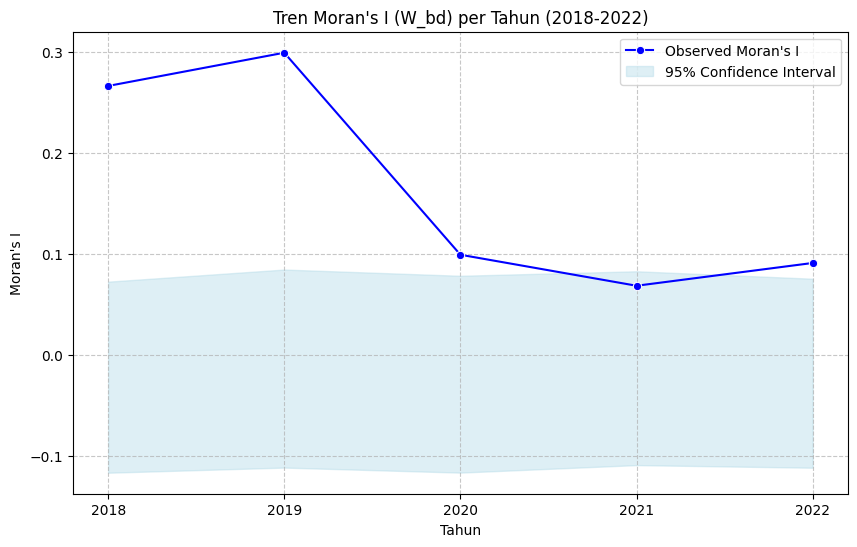

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.lineplot(x='Year', y='I_obs', data=res_bd_year_df, marker='o', label="Observed Moran's I", color='blue')
plt.fill_between(
    res_bd_year_df['Year'],
    res_bd_year_df['ci95_low'],
    res_bd_year_df['ci95_high'],
    color='lightblue', alpha=0.4, label='95% Confidence Interval'
)

plt.title("Tren Moran's I (W_bd) per Tahun (2018-2022)")
plt.xlabel('Tahun')
plt.ylabel("Moran's I")
plt.xticks(res_bd_year_df['Year'])
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend()
plt.show()

## Visualization of Moran-2Di Permutation Distribution for Each W_ST Weight

The following is a histogram plot showing the distribution of Moran-2Di values from permutation simulations for each type of W_ST weight. The red dotted line shows the observed Moran-2Di (`I_obs`), and the green dotted line shows the lower and upper bounds of the 95% confidence interval (`ci95_low`, `ci95_high`).

Processing sheet: W_ST^Q


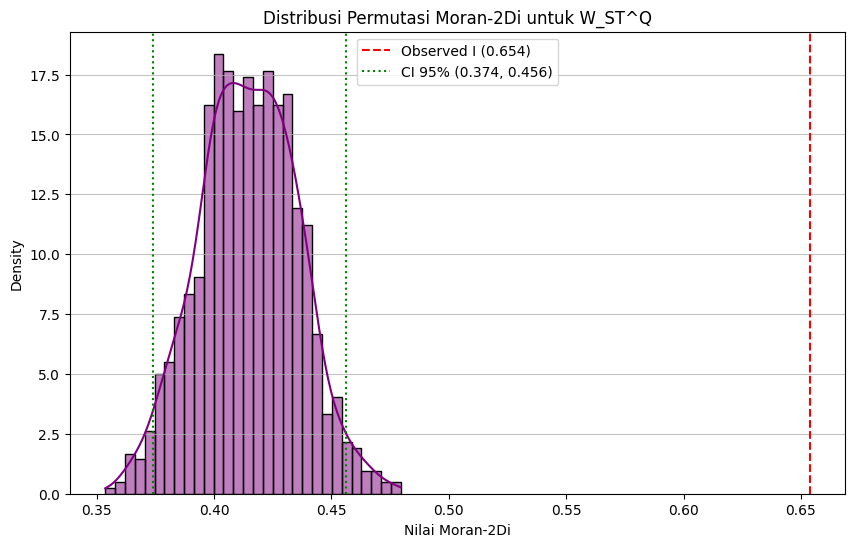

Processing sheet: W_ST^Q10


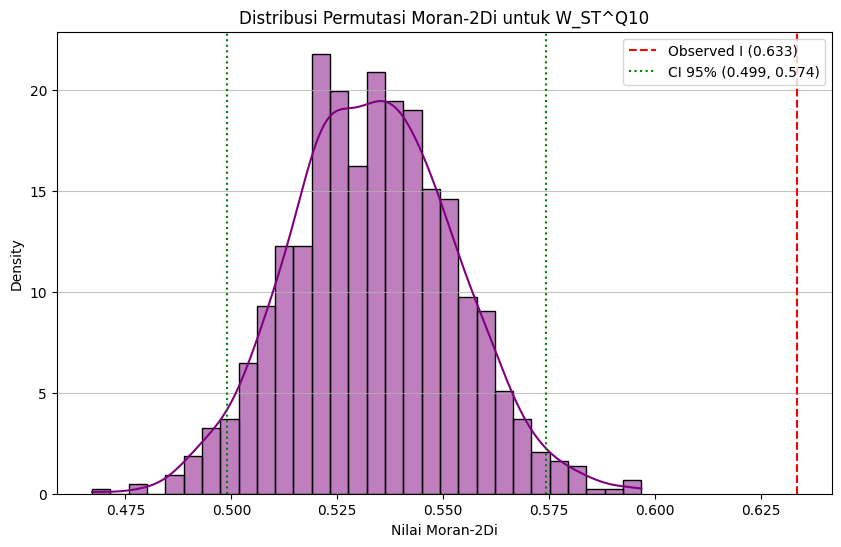

Processing sheet: W_ST^Qq


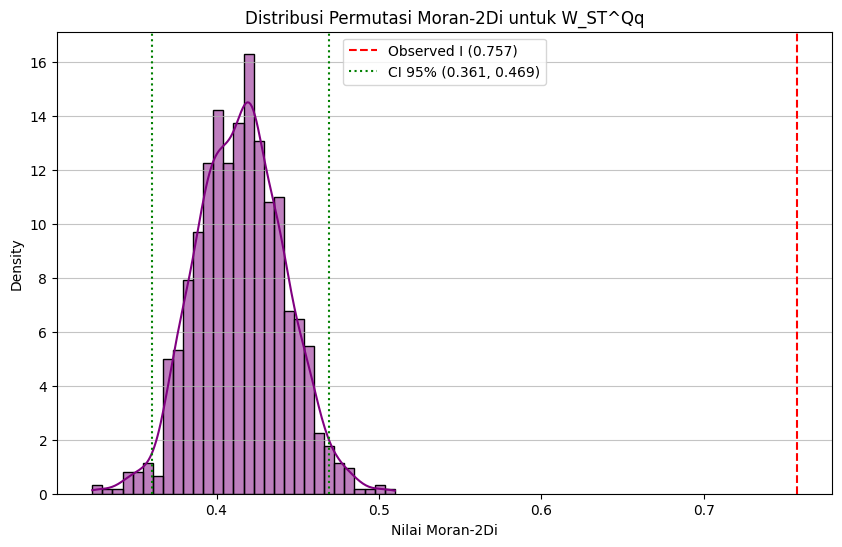

Processing sheet: W_ST^Q10q


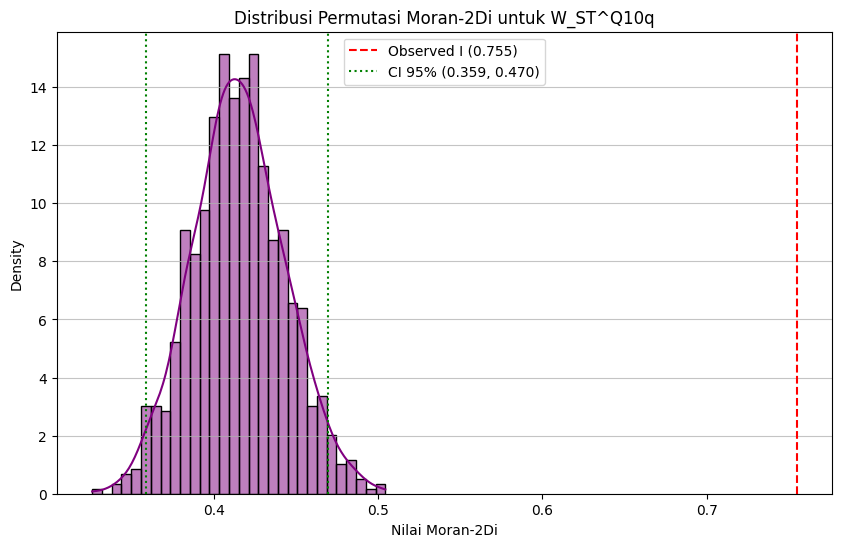

Processing sheet: W_ST^Qr


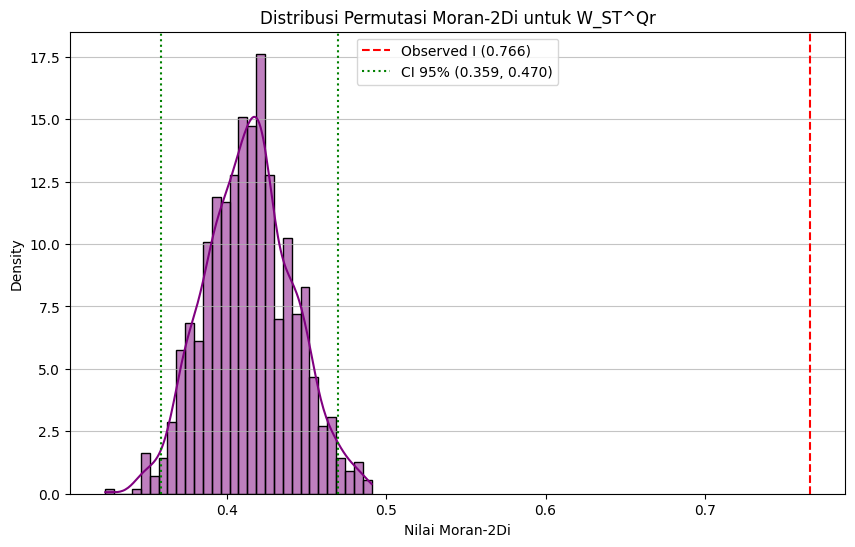

Processing sheet: W_ST^Q10r


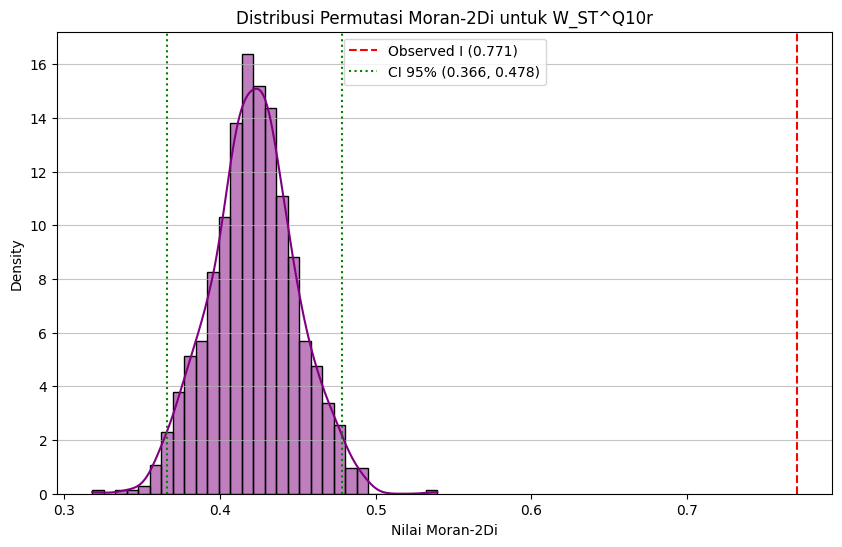

Processing sheet: W_bdst


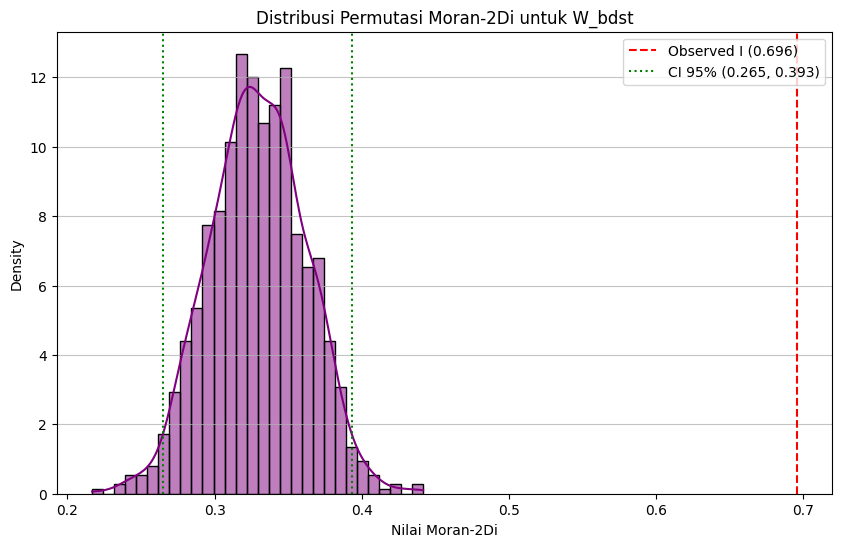

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Filter for W_ST weights (exclude 'W_bd' which is handled separately)
w_st_sheets = [sh for sh in sheets_needed if sh != 'W_bd']

# Ensure N is available from previous cells
# N = len(z)
# years is also available from previous cells
# unique_years = np.unique(years)
# year_indices = {yr: np.where(years == yr)[0] for yr in unique_years}

n_perm = 999
seed = 2026
rng = np.random.default_rng(seed)

for sh in w_st_sheets:
    print(f"Processing sheet: {sh}")
    Wmat = pd.read_excel(W8_PATH, sheet_name=sh, header=None).to_numpy(dtype=float)

    # Get observed I and CI for the current W_ST type from the dataframe
    w_st_data = res_st_df[res_st_df['Weight'] == sh].iloc[0]
    ob_I_st = w_st_data['I_obs']
    ciL_st = w_st_data['ci95_low']
    ciH_st = w_st_data['ci95_high']

    # Regenerate permutation values for the current W_ST for plotting
    I_perm_st = np.empty(n_perm, dtype=float)
    for b in range(n_perm):
        z_perm = z.copy()
        for yr, idx in year_indices.items():
            z_perm[idx] = rng.permutation(z_perm[idx])
        I_perm_st[b] = moran_index(z_perm, Wmat)

    plt.figure(figsize=(10, 6))
    sns.histplot(I_perm_st, bins=30, kde=True, color='purple', stat='density')
    plt.axvline(ob_I_st, color='red', linestyle='--', label=f'Observed I ({ob_I_st:.3f})')
    plt.axvline(ciL_st, color='green', linestyle=':', label=f'CI 95% ({ciL_st:.3f}, {ciH_st:.3f})')
    plt.axvline(ciH_st, color='green', linestyle=':')
    plt.title(f'Distribusi Permutasi Moran-2Di untuk {sh}')
    plt.xlabel('Nilai Moran-2Di')
    plt.ylabel('Density')
    plt.legend()
    plt.grid(axis='y', alpha=0.75)
    plt.show()


## Summary Table of Observed Moran's I for All W_ST Weights

The following table summarizes the observed Moran's I, p-value, permutation mean and standard deviation, and 95% confidence interval for each type of W_ST weight.

In [ ]:
display(res_st_df)

,Weight,I_obs,p_value,perm_mean,perm_std,ci95_low,ci95_high
0,W_ST^Q,0.653762,0.001,0.414587,0.020957,0.373852,0.456039
1,W_ST^Q10,0.633412,0.001,0.535381,0.019726,0.498970,0.574143
2,W_ST^Q10q,0.754757,0.001,0.413346,0.027387,0.358525,0.469582
3,W_ST^Q10r,0.770530,0.001,0.420612,0.028036,0.365789,0.478030
4,W_ST^Qq,0.757131,0.001,0.413745,0.026930,0.360500,0.469300
5,W_ST^Qr,0.765697,0.001,0.413458,0.027687,0.358741,0.469522
6,W_bdst,0.695603,0.001,0.328278,0.032877,0.265116,0.393176
